In [1]:
import os
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'invertebrate', 'marenaria')
pth_out = os.path.join(pth_data, 'results', 'cancer', 'marenaria')
pth_fig = os.path.join(pth, 'figures', 'cancer', 'invertebrate', 'marenaria')
pth_cb = os.path.join(pth_fig, 'colorbars')

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'MarBTN.h5ad'))
adata.obs['sample'] = adata.obs_names.astype('category')
adata

AnnData object with n_obs × n_vars = 8 × 43038
    obs: 'sample'
    uns: 'log1p'
    layers: 'counts'

In [4]:
adata.obs['sample']

01-FFM-28E5            01-FFM-28E5
02-FFM-28E6            02-FFM-28E6
03-FFM-28E7            03-FFM-28E7
SH-1                          SH-1
SH-2                          SH-2
04-FFM-28E5-ASW    04-FFM-28E5-ASW
05-FFM-28E6-ASW    05-FFM-28E6-ASW
06-FFM-28E7-ASW    06-FFM-28E7-ASW
Name: sample, dtype: category
Categories (8, object): ['01-FFM-28E5', '02-FFM-28E6', '03-FFM-28E7', '04-FFM-28E5-ASW', '05-FFM-28E6-ASW', '06-FFM-28E7-ASW', 'SH-1', 'SH-2']

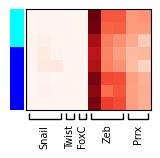

In [5]:
adata.uns['sample_colors'] = ['blue'] * 5 + ['cyan'] * 3
g_plt = {
    'Snail' : ['LOC128242410', 'LOC128243129', 'LOC128243408'],
    'Twist' : ['LOC128243558'],
    'FoxC'  : ['LOC128244946'],
    'Zeb'   : ['LOC128234774', 'LOC128243217', 'LOC128220362'],
    'Prrx'  : ['LOC128227203', 'LOC128226215']}

# expression heatmap
fs, figsize = 7, (1.5 * (11 / 8), 1.5)
hm = sc.pl.heatmap(adata, g_plt, 'sample',
                   cmap = 'Reds',
                   figsize = figsize,
                   show_gene_labels = False,
                   show = False)

ax_hm = hm['heatmap_ax']
ax_grp = hm['groupby_ax']
ax_var = hm['gene_groups_ax']
ax_cb = ax_hm.figure.axes[1]
ax_cb.set_visible(False)

ax_grp.set_yticks([])
ax_grp.set_ylabel('')

for ax in (ax_hm, ax_grp, ax_var):
    ax.invert_yaxis()

for t in ax_var.texts:
    t.set_va('top')
    t.set_fontsize(fs)

for l in ax_var.patches:
    l.set_linewidth(1)

for l in ax_hm.collections:
    l.remove()

pos_hm  = ax_hm.get_position()
pos_var = ax_var.get_position()
ax_var.set_position([pos_var.x0,
                     pos_hm.y0 - pos_var.height - .02,
                     pos_var.width,
                     pos_var.height])

fn = os.path.join(pth_fig, 'expression.pdf')
plt.savefig(fn, bbox_inches = 'tight', dpi = 1200)

/tmp/ipykernel_2957261/2993389579.py:3: UserWarning: Adding colorbar to a different Figure <Figure size 206.25x150 with 4 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax_cb.collections[1], cax = cax)


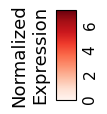

In [12]:
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .905])
cb = plt.colorbar(ax_cb.collections[1], cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('Normalized\nExpression', size = 13, labelpad = 5)
cb.ax.yaxis.set_label_position('left')
cb.set_ticks([0, 2, 4, 6])
cb.ax.tick_params('y', rotation = 90, labelsize = 11, pad = 5)
fn = os.path.join(pth_cb, 'expression.pdf')
plt.savefig(fn, bbox_inches = 'tight')

In [7]:
# save results
df = pd.concat({
      name : pd.DataFrame(adata[:, g].X, columns = g,
                          index = adata.obs_names)
      for name, g in g_plt.items()}, axis = 1).T
df.to_csv(os.path.join(pth_out, 'expression.csv'))